In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
gas_data = pd.read_csv("Nat_Gas.csv")
gas_data['Dates'] = pd.to_datetime(gas_data['Dates'], format='%m/%d/%y')

In [3]:
# converting the dates to numerical values
gas_data['Days'] = (gas_data['Dates'] - gas_data['Dates'].min()).dt.days

In [4]:
# Fitting a regression model
X = gas_data[['Days']]
y = gas_data['Prices']

model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [13]:
# Estimating the price for any past date

target_date = pd.to_datetime(input("Enter a date(MM/DD/YY): "), format='%m/%d/%y')
days = (target_date - gas_data["Dates"].min()).days

days_df = pd.DataFrame({'Days': [days]})
estimated_price = model.predict(days_df)

print(f"{estimated_price[0]:.2f}")

10.34


In [16]:
# Extrapolate One Year in the Future
future_days = np.arange(gas_data['Days'].max(), gas_data['Days'].max() + 365)
future_prices = model.predict(future_days.reshape(-1, 1))

c:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


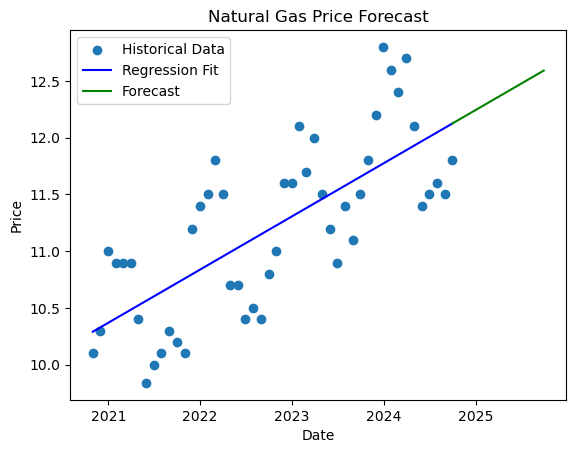

In [11]:
# Visualising the forecast
plt.scatter(gas_data['Dates'], gas_data['Prices'], label='Historical Data')

historical_prices = model.predict(gas_data[['Days']])
plt.plot(gas_data['Dates'], historical_prices, color='blue', label='Regression Fit')

future_dates = gas_data['Dates'].min() + pd.to_timedelta(future_days, unit='D')
plt.plot(future_dates, future_prices, color='green', label='Forecast')

plt.xlabel('Date')
plt.ylabel('Price')
plt.title('Natural Gas Price Forecast')
plt.legend()
plt.show()
